In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import seaborn as sns

In [7]:
# Load Customer Master Data
customer_df = pd.read_csv('/content/Customer_Master_Data.csv')
print("Customer Master Data:")
display(customer_df.head())

# Load Customer Transactions Data
transactions_df = pd.read_csv('/content/Customer_Transactions.csv')
print("\nCustomer Transactions Data:")
display(transactions_df.head())

Customer Master Data:


,CustomerID,Name,Email,Gender,Age,City,MaritalStatus,NumChildren,JoinDate
0,CUST10000,Onkar Bhargava,pkeer@yahoo.com,Male,54,Delhi,Divorced,0,2021-02-22
1,CUST10001,Divit Kohli,mkalita@sarin.com,Female,48,Kolkata,Married,0,2023-12-06
2,CUST10002,Kiara Behl,apteanay@hotmail.com,Male,75,Kolkata,Widowed,2,2023-08-23
3,CUST10003,Vaibhav Sankar,bseshadri@choudhry.info,Male,62,Pune,Divorced,2,2022-11-17
4,CUST10004,Shray D’Alia,bdhillon@toor-mall.com,Male,55,Delhi,Divorced,0,2022-12-04



Customer Transactions Data:


,CustomerID,TransactionDate,TransactionAmount
0,CUST10771,7/31/23,2383.07
1,CUST10100,3/10/24,497.54
2,CUST10031,2/17/25,536.78
3,CUST10987,7/17/23,314.89
4,CUST10831,12/15/24,2543.19


In [8]:
print("=== Customer Master Data Info ===")
customer_df.info()

print("\n=== Customer Transactions Data Info ===")
transactions_df.info()

=== Customer Master Data Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   CustomerID     1000 non-null   object
 1   Name           1000 non-null   object
 2   Email          1000 non-null   object
 3   Gender         1000 non-null   object
 4   Age            1000 non-null   int64 
 5   City           1000 non-null   object
 6   MaritalStatus  1000 non-null   object
 7   NumChildren    1000 non-null   int64 
 8   JoinDate       1000 non-null   object
dtypes: int64(2), object(7)
memory usage: 70.4+ KB

=== Customer Transactions Data Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23050 entries, 0 to 23049
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         23050 non-null  object 
 1   TransactionDate    23050 non-null  obje

In [9]:
# Convert JoinDate and TransactionDate to datetime format
customer_df['JoinDate'] = pd.to_datetime(customer_df['JoinDate'])
transactions_df['TransactionDate'] = pd.to_datetime(transactions_df['TransactionDate'])

# Display updated data types
print("Customer Master Date Type:")
print(customer_df['JoinDate'].dtype)
print("\nTransactions Date Type:")
print(transactions_df['TransactionDate'].dtype)

/tmp/ipykernel_1612/3117931475.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  transactions_df['TransactionDate'] = pd.to_datetime(transactions_df['TransactionDate'])


Customer Master Date Type:
datetime64[ns]

Transactions Date Type:
datetime64[ns]


In [10]:
# Calculate and display the value counts for Gender
gender_counts = customer_df['Gender'].value_value_counts() if hasattr(customer_df['Gender'], 'value_value_counts') else customer_df['Gender'].value_counts()
display(gender_counts)

,count
Gender,
Female,340
Male,332
Not Disclosed,328


In [14]:
# Keep only valid transactions (CustomerID exists in customer_df)
initial_count = len(transactions_df)
valid_transactions_df = transactions_df[transactions_df['CustomerID'].isin(customer_df['CustomerID'])]
filtered_count = len(valid_transactions_df)

print(f"Original number of transactions: {initial_count}")
print(f"Number of valid transactions: {filtered_count}")
print(f"Removed {initial_count - filtered_count} invalid transaction(s).")

# Assign back or store as a clean dataframe
transactions_df = valid_transactions_df
display(transactions_df.head())

Original number of transactions: 23050
Number of valid transactions: 23050
Removed 0 invalid transaction(s).


,CustomerID,TransactionDate,TransactionAmount
0,CUST10771,2023-07-31,2383.07
1,CUST10100,2024-03-10,497.54
2,CUST10031,2025-02-17,536.78
3,CUST10987,2023-07-17,314.89
4,CUST10831,2024-12-15,2543.19


In [16]:
# Join Customer Master Data with Customer Transactions
merged_df = pd.merge(customer_df, transactions_df, on='CustomerID', how='inner')

# Display the combined dataframe's shape and a preview
print(f"Merged DataFrame Shape: {merged_df.shape}")
display(merged_df.tail(15))

Merged DataFrame Shape: (23050, 11)


,CustomerID,Name,Email,Gender,Age,City,MaritalStatus,NumChildren,JoinDate,TransactionDate,TransactionAmount
23035,CUST10999,Alia Sekhon,urvichadha@hotmail.com,Male,67,Hyderabad,Widowed,1,2021-09-07,2023-07-30,2539.21
23036,CUST10999,Alia Sekhon,urvichadha@hotmail.com,Male,67,Hyderabad,Widowed,1,2021-09-07,2024-06-30,56.85
23037,CUST10999,Alia Sekhon,urvichadha@hotmail.com,Male,67,Hyderabad,Widowed,1,2021-09-07,2025-06-22,508.96
23038,CUST10999,Alia Sekhon,urvichadha@hotmail.com,Male,67,Hyderabad,Widowed,1,2021-09-07,2022-09-17,913.62
23039,CUST10999,Alia Sekhon,urvichadha@hotmail.com,Male,67,Hyderabad,Widowed,1,2021-09-07,2023-03-05,1201.20
23040,CUST10999,Alia Sekhon,urvichadha@hotmail.com,Male,67,Hyderabad,Widowed,1,2021-09-07,2025-05-20,377.81
23041,CUST10999,Alia Sekhon,urvichadha@hotmail.com,Male,67,Hyderabad,Widowed,1,2021-09-07,2023-05-24,517.56
23042,CUST10999,Alia Sekhon,urvichadha@hotmail.com,Male,67,Hyderabad,Widowed,1,2021-09-07,2025-03-21,1176.79
23043,CUST10999,Alia Sekhon,urvichadha@hotmail.com,Male,67,Hyderabad,Widowed,1,2021-09-07,2024-01-17,1993.71
23044,CUST10999,Alia Sekhon,urvichadha@hotmail.com,Male,67,Hyderabad,Widowed,1,2021-09-07,2025-07-25,1393.82


In [13]:
# Determine the reference date (1 day after the latest transaction in the dataset)
reference_date = merged_df['TransactionDate'].max() + pd.Timedelta(days=1)
print(f"Reference Date for Recency calculation: {reference_date.date()}")

# Aggregate transaction data by CustomerID
df_rfm = merged_df.groupby('CustomerID').agg(
    LastTransactionDate=('TransactionDate', 'max'),
    Frequency=('TransactionDate', 'count'),
    Monetary=('TransactionAmount', 'sum')
).reset_index()

# Calculate Recency in number of days
df_rfm['Recency'] = (reference_date - df_rfm['LastTransactionDate']).dt.days

# Drop the helper column 'LastTransactionDate' and reorder columns
df_rfm = df_rfm[['CustomerID', 'Recency', 'Frequency', 'Monetary']]

# Preview the calculated RFM metrics
display(df_rfm.head(15))
print(f"df_rfm Shape: {df_rfm.shape}")

Reference Date for Recency calculation: 2025-07-30


,CustomerID,Recency,Frequency,Monetary
0,CUST10000,13,23,21265.49
1,CUST10001,35,30,28654.31
2,CUST10002,18,24,23884.03
3,CUST10003,81,25,24206.03
4,CUST10004,8,19,25565.30
5,CUST10005,24,29,29459.82
6,CUST10006,11,28,27922.36
7,CUST10007,86,15,14957.06
8,CUST10008,3,19,19479.25
9,CUST10009,7,25,22832.83


df_rfm Shape: (1000, 4)


In [18]:
df_rfm.describe()

,Recency,Frequency,Monetary
count,1000.000000,1000.000000,1000.00000
mean,50.794000,23.050000,23053.19966
std,58.124418,4.810472,5622.44101
min,1.000000,6.000000,5052.69000
25%,13.000000,20.000000,18965.46250
50%,32.000000,23.000000,22969.82000
75%,69.000000,26.000000,26827.39250
max,524.000000,38.000000,44784.99000


In [21]:
import pandas as pd
import numpy as np

# Define the scoring logic for Recency (lower is better)
def get_recency_score(r):
    if r <= 30:
        return 5
    elif r <= 60:
        return 4
    elif r <= 120:
        return 3
    elif r <= 240:
        return 2
    else:
        return 1

# Define the scoring logic for Frequency (higher is better)
def get_frequency_score(f):
    if f <= 7:
        return 1
    elif f <= 14:
        return 2
    elif f <= 21:
        return 3
    elif f <= 28:
        return 4
    else:
        return 5

# Define the scoring logic for Monetary (higher is better)
def get_monetary_score(m):
    if m <= 10000:
        return 1
    elif m <= 20000:
        return 2
    elif m <= 30000:
        return 3
    elif m <= 40000:
        return 4
    else:
        return 5

# Apply the functions to create the score columns
df_rfm['Recency_Score'] = df_rfm['Recency'].apply(get_recency_score)
df_rfm['Frequency_Score'] = df_rfm['Frequency'].apply(get_frequency_score)
df_rfm['Monetary_Score'] = df_rfm['Monetary'].apply(get_monetary_score)

# Display the top 15 records to verify the score columns
display(df_rfm.head(15))

,CustomerID,Recency,Frequency,Monetary,Recency_Score,Frequency_Score,Monetary_Score
0,CUST10000,13,23,21265.49,5,4,3
1,CUST10001,35,30,28654.31,4,5,3
2,CUST10002,18,24,23884.03,5,4,3
3,CUST10003,81,25,24206.03,3,4,3
4,CUST10004,8,19,25565.30,5,3,3
5,CUST10005,24,29,29459.82,5,5,3
6,CUST10006,11,28,27922.36,5,4,3
7,CUST10007,86,15,14957.06,3,3,2
8,CUST10008,3,19,19479.25,5,3,2
9,CUST10009,7,25,22832.83,5,4,3


In [22]:
# Concatenate the RFM scores into a single string score
df_rfm['RFM Score'] = (
    df_rfm['Recency_Score'].astype(str) +
    df_rfm['Frequency_Score'].astype(str) +
    df_rfm['Monetary_Score'].astype(str)
)

# Display the top 15 records to verify the new 'RFM Score' column
display(df_rfm.head(15))

,CustomerID,Recency,Frequency,Monetary,Recency_Score,Frequency_Score,Monetary_Score,RFM Score
0,CUST10000,13,23,21265.49,5,4,3,543
1,CUST10001,35,30,28654.31,4,5,3,453
2,CUST10002,18,24,23884.03,5,4,3,543
3,CUST10003,81,25,24206.03,3,4,3,343
4,CUST10004,8,19,25565.30,5,3,3,533
5,CUST10005,24,29,29459.82,5,5,3,553
6,CUST10006,11,28,27922.36,5,4,3,543
7,CUST10007,86,15,14957.06,3,3,2,332
8,CUST10008,3,19,19479.25,5,3,2,532
9,CUST10009,7,25,22832.83,5,4,3,543


In [24]:
def assign_segment(row):
    r = row['Recency_Score']
    f = row['Frequency_Score']
    m = row['Monetary_Score']

    # Champions: R 4-5, F 4-5, M 4-5
    if r in [4, 5] and f in [4, 5] and m in [4, 5]:
        return 'Champions'

    # Loyal Customers: F 4-5, R 2-5
    if f in [4, 5] and r in [2, 3, 4, 5]:
        return 'Loyal Customers'

    # Potential Loyalist: R 4-5, F 2-3
    if r in [4, 5] and f in [2, 3]:
        return 'Potential Loyalist'

    # At Risk: R 1-2, F 3-5
    if r in [1, 2] and f in [3, 4, 5]:
        return 'At Risk'

    # Lost: R 1, f 1-2, M 1-2
    if r == 1 and f in [1, 2] and m in [1, 2]:
        return 'Lost'

    # Big Spenders: M 4-5, F 2-3, R 3-4
    if m in [4, 5] and f in [2, 3] and r in [3, 4]:
        return 'Big Spenders'

    return 'Others'

# Apply the segmentation logic
df_rfm['Customer Segment'] = df_rfm.apply(assign_segment, axis=1)

# Display segment value counts and sample data
print("Customer Segment Counts:")
print(df_rfm['Customer Segment'].value_counts())
display(df_rfm.head(15))

Customer Segment Counts:
Customer Segment
Loyal Customers       542
Potential Loyalist    248
Champions              84
Others                 77
At Risk                47
Lost                    2
Name: count, dtype: int64


,CustomerID,Recency,Frequency,Monetary,Recency_Score,Frequency_Score,Monetary_Score,RFM Score,Customer Segment
0,CUST10000,13,23,21265.49,5,4,3,543,Loyal Customers
1,CUST10001,35,30,28654.31,4,5,3,453,Loyal Customers
2,CUST10002,18,24,23884.03,5,4,3,543,Loyal Customers
3,CUST10003,81,25,24206.03,3,4,3,343,Loyal Customers
4,CUST10004,8,19,25565.30,5,3,3,533,Potential Loyalist
5,CUST10005,24,29,29459.82,5,5,3,553,Loyal Customers
6,CUST10006,11,28,27922.36,5,4,3,543,Loyal Customers
7,CUST10007,86,15,14957.06,3,3,2,332,Others
8,CUST10008,3,19,19479.25,5,3,2,532,Potential Loyalist
9,CUST10009,7,25,22832.83,5,4,3,543,Loyal Customers


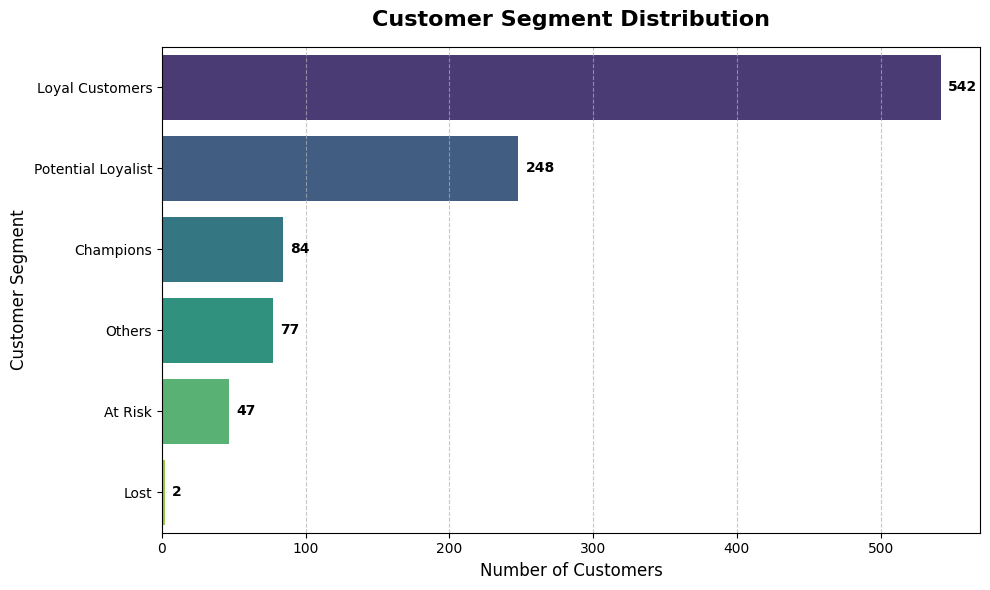

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate segment counts
segment_counts = df_rfm['Customer Segment'].value_counts().reset_index()
segment_counts.columns = ['Customer Segment', 'Count']

# Create the plot
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Count',
    y='Customer Segment',
    data=segment_counts,
    hue='Customer Segment',
    palette='viridis',
    legend=False
)

# Add titles and labels
plt.title('Customer Segment Distribution', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Number of Customers', fontsize=12)
plt.ylabel('Customer Segment', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Add value labels to each bar
for index, value in enumerate(segment_counts['Count']):
    plt.text(value + 5, index, str(value), va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Merge demographic age data with our RFM customer segments
df_customer_age_segment = pd.merge(
    df_rfm[['CustomerID', 'Customer Segment']],
    customer_df[['CustomerID', 'Age']],
    on='CustomerID',
    how='inner'
)

# 2. Define Age Brackets
bins = [0, 30, 45, 60, 100]
labels = ['Under 30', '30-45', '46-60', 'Over 60']
df_customer_age_segment['Age Bracket'] = pd.cut(df_customer_age_segment['Age'], bins=bins, labels=labels)

# 3. Create a pivot table showing counts for each Segment and Age Bracket
age_segment_pivot = df_customer_age_segment.groupby(['Customer Segment', 'Age Bracket']).size().unstack(fill_value=0)

# Calculate percentages for better representation in the plot
age_segment_pct = age_segment_pivot.div(age_segment_pivot.sum(axis=1), axis=0) * 100

# Display the absolute numbers
print("Absolute counts of customers in each age bracket by segment:")
display(age_segment_pivot)


Absolute counts of customers in each age bracket by segment:


/tmp/ipykernel_1612/3520903710.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_segment_pivot = df_customer_age_segment.groupby(['Customer Segment', 'Age Bracket']).size().unstack(fill_value=0)


Age Bracket,Under 30,30-45,46-60,Over 60
Customer Segment,,,,
At Risk,9,17,9,12
Champions,21,22,25,16
Lost,0,1,0,1
Loyal Customers,113,147,144,138
Others,18,16,19,24
Potential Loyalist,62,70,59,57


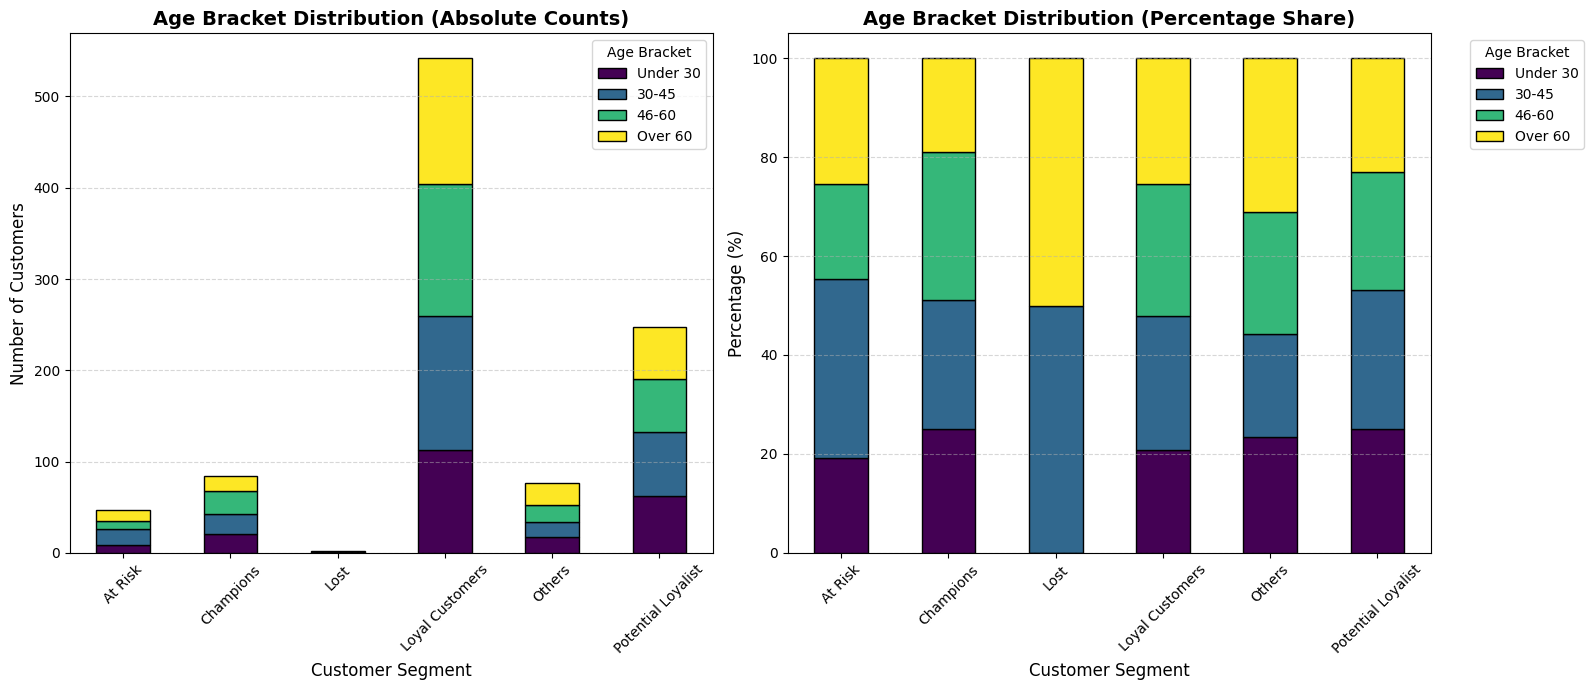

In [28]:
# 4. Generate the Visualization (Stacked Bar Chart)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Plot Absolute Counts
age_segment_pivot.plot(kind='bar', stacked=True, ax=axes[0], colormap='viridis', edgecolor='black')
axes[0].set_title('Age Bracket Distribution (Absolute Counts)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Customers', fontsize=12)
axes[0].set_xlabel('Customer Segment', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Plot Percentage Share
age_segment_pct.plot(kind='bar', stacked=True, ax=axes[1], colormap='viridis', edgecolor='black')
axes[1].set_title('Age Bracket Distribution (Percentage Share)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Percentage (%)', fontsize=12)
axes[1].set_xlabel('Customer Segment', fontsize=12)
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
axes[1].legend(title='Age Bracket', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [29]:
# Merge demographic age data with the calculated RFM monetary data
df_customer_spending = pd.merge(
    df_rfm[['CustomerID', 'Monetary']],
    customer_df[['CustomerID', 'Age']],
    on='CustomerID',
    how='inner'
)

# Define the same Age Brackets as used previously
bins = [0, 30, 45, 60, 100]
labels = ['Under 30', '30-45', '46-60', 'Over 60']
df_customer_spending['Age Bracket'] = pd.cut(df_customer_spending['Age'], bins=bins, labels=labels)

# Calculate aggregation metrics per Age Bracket
spending_by_age = df_customer_spending.groupby('Age Bracket', observed=False).agg(
    Total_Spending=('Monetary', 'sum'),
    Average_Spending=('Monetary', 'mean'),
    Median_Spending=('Monetary', 'median'),
    Customer_Count=('CustomerID', 'count')
).reset_index()

# Display the aggregated metrics
display(spending_by_age)

,Age Bracket,Total_Spending,Average_Spending,Median_Spending,Customer_Count
0,Under 30,5183940.31,23246.369103,23137.080,223
1,30-45,6364600.50,23313.554945,23207.570,273
2,46-60,5883298.49,22981.634727,22860.295,256
3,Over 60,5621360.36,22666.775645,22405.865,248


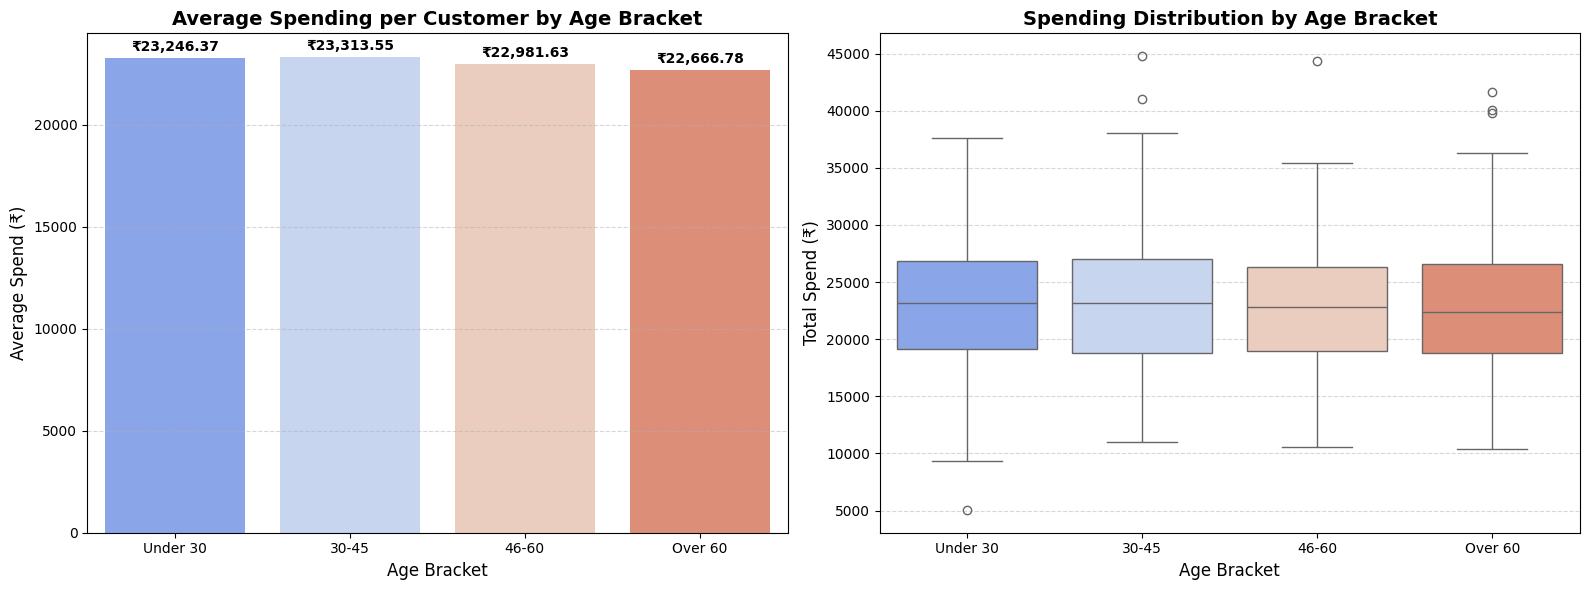

In [32]:
# Create visualization of spending by age bracket
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Bar Chart of Average Spending
sns.barplot(
    x='Age Bracket',
    y='Average_Spending',
    data=spending_by_age,
    ax=axes[0],
    hue='Age Bracket',
    palette='coolwarm',
    legend=False
)
axes[0].set_title('Average Spending per Customer by Age Bracket', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Average Spend (₹)', fontsize=12)
axes[0].set_xlabel('Age Bracket', fontsize=12)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Add values above the bars with rupee symbol
for bar in axes[0].patches:
    height = bar.get_height()
    axes[0].annotate(f'₹{height:,.2f}',
                     xy=(bar.get_x() + bar.get_width() / 2, height),
                     xytext=(0, 3),  # 3 points vertical offset
                     textcoords="offset points",
                     ha='center', va='bottom', fontsize=10, fontweight='bold')

# 2. Box Plot to show distribution of spending within each age bracket
sns.boxplot(
    x='Age Bracket',
    y='Monetary',
    data=df_customer_spending,
    ax=axes[1],
    hue='Age Bracket',
    palette='coolwarm',
    legend=False
)
axes[1].set_title('Spending Distribution by Age Bracket', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Total Spend (₹)', fontsize=12)
axes[1].set_xlabel('Age Bracket', fontsize=12)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [33]:
# Merge demographic marital status data with our RFM monetary spending data
df_customer_marital_spending = pd.merge(
    df_rfm[['CustomerID', 'Monetary']],
    customer_df[['CustomerID', 'MaritalStatus']],
    on='CustomerID',
    how='inner'
)

# Calculate aggregation metrics per Marital Status
spending_by_marital = df_customer_marital_spending.groupby('MaritalStatus').agg(
    Total_Spending=('Monetary', 'sum'),
    Average_Spending=('Monetary', 'mean'),
    Median_Spending=('Monetary', 'median'),
    Customer_Count=('CustomerID', 'count')
).reset_index()

# Display the aggregated metrics
display(spending_by_marital)

,MaritalStatus,Total_Spending,Average_Spending,Median_Spending,Customer_Count
0,Divorced,5861664.88,23446.659520,23518.765,250
1,Married,5235679.35,23373.568527,22613.600,224
2,Single,5498101.28,22350.005203,22493.305,246
3,Widowed,6457754.15,23063.407679,23212.570,280


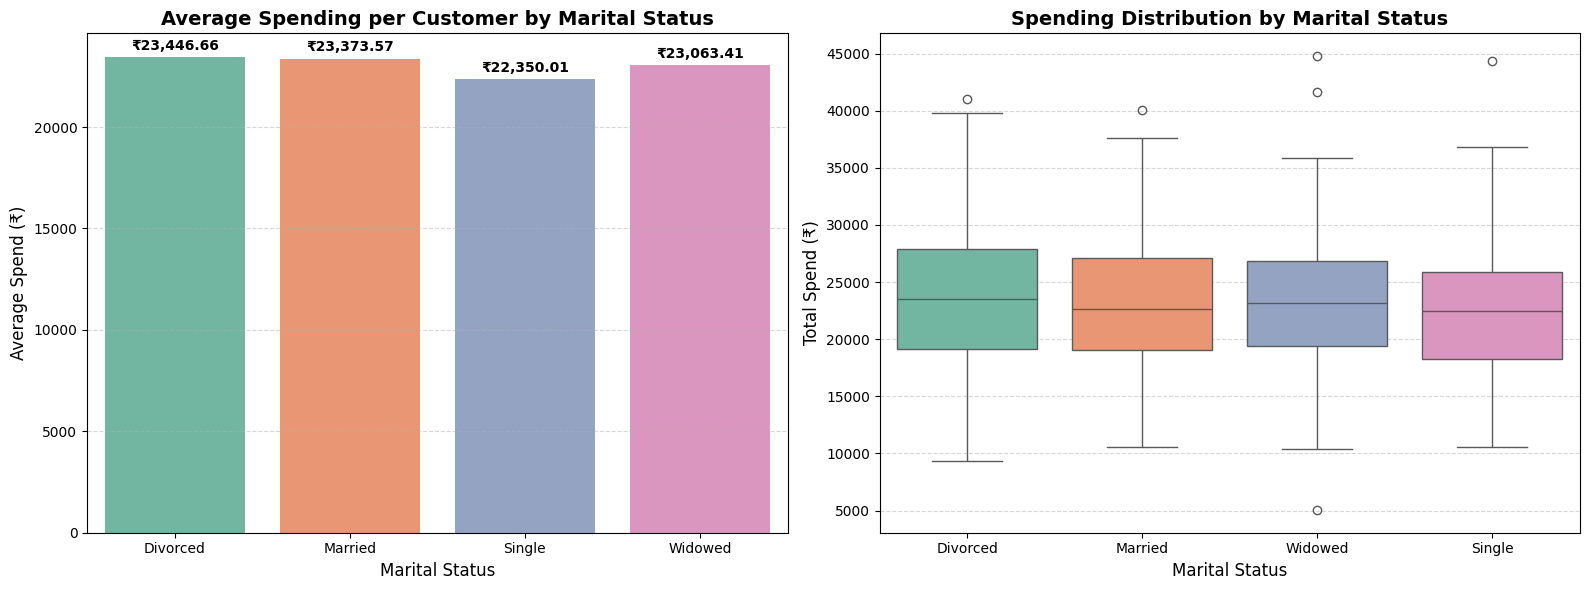

In [36]:
# Create visualization of spending by marital status
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Bar Chart of Average Spending by Marital Status
sns.barplot(
    x='MaritalStatus',
    y='Average_Spending',
    data=spending_by_marital,
    ax=axes[0],
    hue='MaritalStatus',
    palette='Set2',
    legend=False
)
axes[0].set_title('Average Spending per Customer by Marital Status', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Average Spend (₹)', fontsize=12)
axes[0].set_xlabel('Marital Status', fontsize=12)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Add values above the bars with rupee symbol
for bar in axes[0].patches:
    height = bar.get_height()
    axes[0].annotate(f'₹{height:,.2f}',
                     xy=(bar.get_x() + bar.get_width() / 2, height),
                     xytext=(0, 3),  # 3 points vertical offset
                     textcoords="offset points",
                     ha='center', va='bottom', fontsize=10, fontweight='bold')

# 2. Box Plot to show distribution of spending within each marital group
sns.boxplot(
    x='MaritalStatus',
    y='Monetary',
    data=df_customer_marital_spending,
    ax=axes[1],
    hue='MaritalStatus',
    palette='Set2',
    legend=False
)
axes[1].set_title('Spending Distribution by Marital Status', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Total Spend (₹)', fontsize=12)
axes[1].set_xlabel('Marital Status', fontsize=12)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()